# 17 — What-ifs: policy and stress (Part 3, Stage 7)

**Does:** runs the best-response equilibrium of all 24 strategic firms (≥ 1 GW) under policy changes and stress scenarios, on a 60-day sample spread evenly over spare capacity.

**Runs:** `src/run_part3.py stage7` (36 min on 9 processes) → `strategic_whatif_daily.csv`. **Plan:** `docs/part3_plan.md`, Stage 7. **Logged in:** `docs/model_log.md`, Step 28.

## What-ifs (Step 28)

| What-if | Change |
|---|---|
| Base | 24 firms, bid only, everyone else at cost |
| Cap Rs 5,000 | Price cap lowered from Rs 10,000; bids stop at Rs 4,490 (5,000 × 0.9 − 10, the Step 23 loss margin) |
| Contracts 50% | Every firm has sold half of its at-cost output forward at a fixed price (contract for differences), so on that half a higher spot price earns it nothing |
| Coal −10% | Coal availability × 0.9 in every state (coal shortage) |
| Demand +5% | Every state's demand × 1.05 |

Each what-if's competitive benchmark (`_cost` columns) is re-run under the same change, so markups compare like with like.

**Cycles (decision B):** on a day where the firms keep undercutting each other, the result is wherever the 5th round stopped, flagged `Status = cycle`. Averages are shown over all days and over days that settle under every what-if.

Not run (logged as limits): must-offer (Stages 4–7 already bid only, no withholding), splitting the largest firm (the LP keys blocks by state and fuel, so two owners of one block need a new block type), transmission limits (the model has none).

**Check before the run:** at the Rs 5,000 cap, UP and Maharashtra bidding the highest allowed bid on 30 Jan 2025 leave no unserved demand and keep every price ≤ Rs 5,000 (`tests/test_bidding.py`).

**Hypotheses (written before the run):** the lower cap bites only on the tightest days; contracts roughly halve markups; a coal shortage and higher demand raise market power **more** than they raise the competitive price; with 24 firms, prices end up close to the 5-firm sample study's on comparable days.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dispatch import PROCESSED

crore = 1e7
path = PROCESSED / "strategic_whatif_daily.csv"
if not path.exists():
    raise FileNotFoundError("Run `.venv/bin/python src/run_part3.py stage7` first (36 min)")
w = pd.read_csv(path, parse_dates=["Date"])
national = pd.read_csv(PROCESSED / "market_structure_national_daily.csv", parse_dates=["Date"]).set_index("Date")
w["Spare"] = w["Date"].map(national["Tightness"])
w["Markup_pct"] = 100 * (w["Price_avg_eq"] / w["Price_avg_cost"] - 1)
w["Extra_consumer_cr_h"] = (w["Consumer_cost_eq"] - w["Consumer_cost_cost"]) / crore

print(w.groupby("What_if", sort=False)["Status"].value_counts().unstack(fill_value=0))
print("Unserved MW, max: at cost", w["Unserved_MW_cost"].max(), "| equilibrium", w["Unserved_MW_eq"].max())

settled_all = w.groupby("Date")["Status"].apply(lambda s: (s == "converged").all())
settled_days = settled_all[settled_all].index
print(f"Days that settle under every what-if: {len(settled_days)} of {w['Date'].nunique()}")

def table(df):
    t = df.groupby("What_if", sort=False).agg(
        Competitive_price=("Price_avg_cost", "mean"), Equilibrium_price=("Price_avg_eq", "mean"),
        Avg_markup_pct=("Markup_pct", "mean"), Max_markup_pct=("Markup_pct", "max"),
        Days_markup_over_5pct=("Markup_pct", lambda m: int((m > 5).sum())),
        Firms_marking_up=("Firms_marking_up", "mean"),
        Extra_consumer_cr_h=("Extra_consumer_cr_h", "mean"))
    base = t.loc["Base"]
    t["Competitive_vs_base_%"] = 100 * (t["Competitive_price"] / base["Competitive_price"] - 1)
    t["Equilibrium_vs_base_%"] = 100 * (t["Equilibrium_price"] / base["Equilibrium_price"] - 1)
    return t.round(1)

print("All 60 days:"); display(table(w))
print("Days that settle under every what-if:"); display(table(w[w["Date"].isin(settled_days)]))

Status         converged  round limit  cycle
What_if                                     
Base                  41           16      3
Cap Rs 5,000          41           15      4
Contracts 50%         37           16      7
Coal -10%             42           11      7
Demand +5%            46            8      6
Unserved MW, max: at cost 6449.06740990459 | equilibrium 6449.06740990459
Days that settle under every what-if: 21 of 60
All 60 days:


,Competitive_price,Equilibrium_price,Avg_markup_pct,Max_markup_pct,Days_markup_over_5pct,Firms_marking_up,Extra_consumer_cr_h,Competitive_vs_base_%,Equilibrium_vs_base_%
What_if,,,,,,,,,
Base,3139.1,3975.4,24.5,139.6,42,2.0,19.1,0.0,0.0
"Cap Rs 5,000",3139.1,3492.8,11.6,23.0,42,2.0,7.8,0.0,-12.1
Contracts 50%,3139.1,3612.3,13.9,137.1,19,2.0,10.9,0.0,-9.1
Coal -10%,3711.6,5663.0,51.9,141.4,45,1.6,44.3,18.2,42.5
Demand +5%,3533.7,5383.5,50.4,140.7,44,1.6,44.3,12.6,35.4


Days that settle under every what-if:


,Competitive_price,Equilibrium_price,Avg_markup_pct,Max_markup_pct,Days_markup_over_5pct,Firms_marking_up,Extra_consumer_cr_h,Competitive_vs_base_%,Equilibrium_vs_base_%
What_if,,,,,,,,,
Base,3201.6,4236.8,29.9,138.6,14,1.0,23.9,0.0,0.0
"Cap Rs 5,000",3201.6,3585.7,12.6,22.9,14,1.0,8.5,0.0,-15.4
Contracts 50%,3201.6,4130.2,26.4,137.1,10,1.0,21.6,0.0,-2.5
Coal -10%,4401.5,5960.8,41.9,141.4,10,1.0,35.2,37.5,40.7
Demand +5%,4066.3,5464.4,37.2,140.5,10,1.1,33.5,27.0,29.0


Average markup (%) by spare capacity (Base days' spare):


What_if,Base,"Cap Rs 5,000",Contracts 50%,Coal -10%,Demand +5%
Band,,,,,
≤10%,121.1,14.5,67.5,57.9,91.5
10–15%,10.4,8.5,6.9,133.7,133.2
15–20%,7.0,7.0,5.1,55.7,23.2
20–30%,19.1,19.1,9.3,13.2,15.5
>30%,7.2,6.9,4.6,11.0,10.8


Days per band: {'≤10%': 7, '10–15%': 13, '15–20%': 11, '20–30%': 17, '>30%': 12}


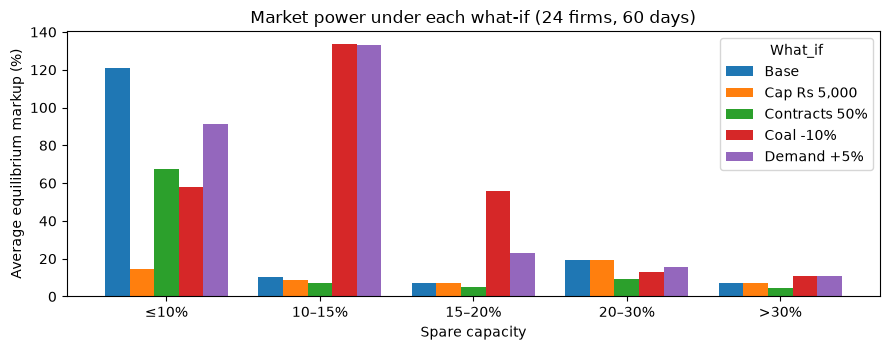

Average markup (%) by band: 5 firms (sample study, 2 days per band) vs 24 firms (Base):


,5 firms,24 firms
Band,,
≤10%,138.4,121.1
10–15%,2.6,10.4
15–20%,9.4,7.0
20–30%,20.0,19.1
>30%,8.7,7.2


In [2]:
bands = pd.cut(w["Spare"], [0, 0.10, 0.15, 0.20, 0.30, 1.0], labels=["≤10%", "10–15%", "15–20%", "20–30%", ">30%"])
by_band = w.assign(Band=bands).pivot_table(index="Band", columns="What_if", values="Markup_pct", aggfunc="mean", observed=True)
print("Average markup (%) by spare capacity (Base days' spare):"); display(by_band[w["What_if"].unique()].round(1))
print("Days per band:", bands[w["What_if"] == "Base"].value_counts().sort_index().to_dict())

fig, ax = plt.subplots(figsize=(9, 3.6))
by_band[w["What_if"].unique()].plot.bar(ax=ax, rot=0, width=0.8)
ax.set_ylabel("Average equilibrium markup (%)"); ax.set_xlabel("Spare capacity")
ax.set_title("Market power under each what-if (24 firms, 60 days)")
plt.tight_layout(); plt.show()

# Comparison with the 5-firm sample study by spare-capacity band (the two samples share no days)
sample = pd.read_csv(PROCESSED / "strategic_sample_results.csv", parse_dates=["Date"])
s5 = sample[sample["Experiment"] == "together"].drop_duplicates("Date")
s5 = s5[s5["Band"] != "Peak day"]
s5_band = (100 * (s5["Price_avg"] / s5["Price_avg_cost"] - 1)).groupby(s5["Band"]).mean()
s5_band = s5_band.rename(index={"< 10%": "≤10%", "≥ 30%": ">30%"})
print("Average markup (%) by band: 5 firms (sample study, 2 days per band) vs 24 firms (Base):")
display(pd.DataFrame({"5 firms": s5_band, "24 firms": by_band["Base"]}).reindex(by_band.index).round(1))

## Stage 7 conclusions

**Run:** 36 min (9 processes), 300 equilibria. Each what-if's competitive benchmark moves as it should: the cap and contracts leave it at Rs 3,139; Coal −10% raises it 18%, Demand +5% 13%. Unserved demand only on 5 rows (Coal −10% on 3 winter days, Demand +5% on 2): **real shortages**, present with everyone bidding cost and no firm marking up.

**Many days don't settle with 24 firms.** Base: 41 of 60 converge, 16 hit the 5-round limit, 3 cycle (decision B: the result is where round 5 stopped). Settled days have exactly one firm marking up (the price umbrella); unsettled days have 3–6 firms still adjusting. Only 21 days settle under all five what-ifs, so every result is shown over all days and over those 21.

| What-if | Avg markup, all 60 days | Avg markup, 21 settled days | Highest markup | Extra consumer cost (Rs crore/h) |
|---|---|---|---|---|
| Base | 24.5% | 29.9% | 140% | 19.1 |
| Cap Rs 5,000 | 11.6% | 12.6% | 23% | 7.8 |
| Contracts 50% | 13.9% | 26.4% | 137% | 10.9 |
| Coal −10% | 51.9% | 41.9% | 141% | 44.3 |
| Demand +5% | 50.4% | 37.2% | 141% | 44.3 |

| Hypothesis | Result |
|---|---|
| The lower cap bites only on the tightest days | ❌ It works more widely: average markup halves, the highest falls from 140% to 23% (tightest days: 121% → 15%) |
| Contracts roughly halve markups | ⚠️ Not robust: halved over all days (24.5% → 13.9%), but only 30% → 26% on settled days. The halving comes mostly from contracts changing where unsettled days end. On the tightest days 121% → 68%: a half-contracted firm still marks up |
| Stress raises market power more than the competitive price | ✅ Coal −10%: competitive +18%, equilibrium +43%; Demand +5%: +13% vs +35%. Stress turns 10–15%-spare days into pivotal ones (markup 10% → 133%); consumers' extra cost 2.3× Base |
| 24 firms ≈ the 5-firm sample study | ✅ by band (no common days): tightest days +121% vs +138%; other bands within ~10 points |

- **A price cap is the most effective tool here**, because market power in this market is concentrated in the few tight days where a firm can bid near the cap
- **Scarcity is a market-power multiplier:** a modest coal shortage or demand rise more than doubles the markup consumers pay on top of the higher competitive price
- **Caveats:** 60 days; one firm per state; bid only; a third of the days don't settle within 5 rounds, so what-if differences on those days partly reflect where the iteration stopped